# Interneuron knowledge base → MPR neural-mass priors

This notebook builds the SQLite knowledge base from `seed/*.csv` and the netlist, then shows how the ODE pulls a parameter bundle $\Theta_i$ for each of the 53 inhibitory populations **with provenance**.

Evidence levels returned by the resolver:

| rank | level | meaning |
|---|---|---|
| 0 | `cell` | claim/prior attached to the exact netlist population |
| 1+d | `taxon(d)` | claim/prior on the mapped family, `d` levels up |
| 50 | `subtype_mixture` | family unresolved (bare *Basket*): moment-matched mixture of subtypes |
| 55 | `sibling_mixture` | placeholder family (e.g. `DT_UNRESOLVED`): mixture of sibling families with data |
| 99 | `global` | modeling default (broad, flagged as assumption) |

Literature numbers come from Pelkey et al. 2017 (*Physiol Rev* 97:1619), including Table 1 (Tricoire et al. 2011 clusters). Anything without a page locator is a modeling assumption.

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

KB_DIR = Path.cwd()                       # run from database_design/kb
DB = KB_DIR / "hippocampal_interneuron_kb.sqlite"
NETLIST = KB_DIR.parent / "mij_netlist.csv"
sys.path.insert(0, str(KB_DIR))

import build_kb
build_kb.main(["--netlist", str(NETLIST), "--out", str(DB)])

from resolver import KB
import query                               # adds kb.describe() / kb.find()
kb = KB(DB)
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)

        cell_types: 85
      interneurons: 53
              taxa: 26
            claims: 417
 distribution_bins: 125
             edges: 1641
 review_references: 1282
  model_parameters: 28
            priors: 26
       derivations: 12
wrote /tmp/claude-0/nbrun/kb/hippocampal_interneuron_kb.sqlite


## 1. The 53 interneurons and their family mapping

In [2]:
pd.read_sql("SELECT * FROM v_interneuron ORDER BY region, netlist_name", kb.db)

,cell_type_id,netlist_name,region,name_core,primary_taxon,taxon_confidence
0,1,CA1 Axo Axonic,CA1,Axo Axonic,AAC,0.95
1,2,CA1 Back Projection,CA1,Back Projection,PROJECTING,0.80
2,3,CA1 Basket,CA1,Basket,BASKET,0.90
3,4,CA1 Basket CCK+,CA1,Basket CCK+,CCKBC,0.95
4,5,CA1 Bistratified,CA1,Bistratified,BIC,0.95
5,6,CA1 Horizontal Axo Axonic,CA1,Horizontal Axo Axonic,AAC,0.85
6,7,CA1 Horizontal Basket,CA1,Horizontal Basket,BASKET,0.70
7,8,CA1 Ivy,CA1,Ivy,IVY,0.95
8,9,CA1 LMR,CA1,LMR,DT_UNRESOLVED,0.30
9,10,CA1 Neurogliaform,CA1,Neurogliaform,NGFC,0.95


## 2. One population's parameter bundle Θᵢ
`specificity` says where each number came from; `evidence` gives subject:page.

In [3]:
def show_bundle(cell):
    rows = []
    for k, p in kb.bundle(cell).items():
        r = p.row(); r["param"] = k if isinstance(k, str) else f"{k[0]}[{k[1]}]"
        rows.append(r)
    cols = ["param", "dist", "p1", "p2", "median", "confidence", "specificity", "basis", "evidence"]
    return pd.DataFrame(rows)[cols].round(4)

show_bundle("CA1 O LM")

,param,dist,p1,p2,median,confidence,specificity,basis,evidence
0,Delta,lognormal,0.1096,0.5688,0.1096,0.5985,OLM_FAMILY,derived_from_claims,OLM_FAMILY:Table 1 (p.1646); OLM_FAMILY:Table 1 (p.1646)
1,U_A,beta,0.5000,4.0000,0.5000,0.1500,global,modeling_assumption,global:
2,U_B,halfnormal,0.0500,NaN,0.0337,0.1500,global,modeling_assumption,global:
3,alpha_eta[DOR],truncnormal,-1.0000,0.5777,-1.0302,0.6650,OLM,derived_from_claims,OLM:p.1692
4,alpha_eta[M1],truncnormal,1.0000,0.5777,1.0302,0.6650,OLM,derived_from_claims,OLM:p.1688
5,alpha_eta[MOR],normal,0.0000,0.1058,0.0000,0.5225,OLM,derived_from_claims,OLM:p.1692
6,b,lognormal,74.0376,0.3595,74.0376,0.5985,OLM_FAMILY,derived_from_claims,OLM_FAMILY:Table 1 (p.1646); OLM_FAMILY:Table 1 (p.1646); OLM_FAMILY:Table 1...
7,beta_CB1[CB1],halfnormal,1.0000,NaN,0.6745,0.1500,global,modeling_assumption,global:
8,eta,normal,-0.2777,0.0943,-0.2777,0.5985,OLM_FAMILY,derived_from_claims,OLM_FAMILY:Table 1 (p.1646); OLM_FAMILY:Table 1 (p.1646)
9,gamma_in,lognormal,9.2276,0.3385,9.2276,0.5985,OLM_FAMILY,derived_from_claims,OLM_FAMILY:Table 1 (p.1646); OLM_FAMILY:Table 1 (p.1646); OLM_FAMILY:Table 1...


In [4]:
show_bundle("CA1 Basket CCK+")

,param,dist,p1,p2,median,confidence,specificity,basis,evidence
0,Delta,lognormal,0.0639,0.5750,0.0639,0.570,CCKBC,derived_from_claims,CCKBC:Table 1 (p.1646); CCKBC:Table 1 (p.1646)
1,U_A,beta,0.5000,4.0000,0.5000,0.150,global,modeling_assumption,global:
2,U_B,halfnormal,0.0500,NaN,0.0337,0.150,global,modeling_assumption,global:
3,alpha_eta[M3],truncnormal,1.0000,0.5777,1.0302,0.665,CCKBC,derived_from_claims,CCKBC:p.1689
4,alpha_rel[GABAB],truncnormal,-1.0000,0.5979,-1.0354,0.570,CCKBC,derived_from_claims,CCKBC:p.1626
5,alpha_rel[MOR],normal,0.0000,0.1052,0.0000,0.570,CCKBC,derived_from_claims,CCKBC:p.1692
6,b,lognormal,24.9134,0.3539,24.9134,0.570,CCKBC,derived_from_claims,CCKBC:Table 1 (p.1646); CCKBC:Table 1 (p.1646); CCKBC:Table 1 (p.1646); CCKB...
7,beta_CB1[CB1],truncnormal,1.5000,0.7385,1.5195,0.475,CCKBC,modeling_assumption,CCKBC:p.1685-1686
8,eta,normal,-0.1052,0.0411,-0.1052,0.570,CCKBC,derived_from_claims,CCKBC:Table 1 (p.1646); CCKBC:Table 1 (p.1646)
9,gamma_in,lognormal,5.7574,0.3443,5.7574,0.570,CCKBC,derived_from_claims,CCKBC:Table 1 (p.1646); CCKBC:Table 1 (p.1646); CCKBC:Table 1 (p.1646)


Bare *Basket* stays molecularly unresolved: intrinsic priors span PVBC and CCKBC, and no CB1-specific prior is inherited.

In [5]:
show_bundle("CA1 Basket")

,param,dist,p1,p2,median,confidence,specificity,basis,evidence
0,Delta,lognormal,0.0753,0.6512,0.0753,0.3038,"mixture[PVBC,CCKBC]",child_mixture,PVBC:Table 1 (p.1646); PVBC:Table 1 (p.1646); CCKBC:Table 1 (p.1646); CCKBC:...
1,U_A,beta,0.5000,4.0000,0.5000,0.1500,global,modeling_assumption,global:
2,U_B,halfnormal,0.0500,NaN,0.0337,0.1500,global,modeling_assumption,global:
3,b,lognormal,11.5730,0.9022,11.5730,0.3038,"mixture[PVBC,CCKBC]",child_mixture,PVBC:Table 1 (p.1646); PVBC:Table 1 (p.1646); PVBC:Table 1 (p.1646); PVBC:Ta...
4,beta_CB1[CB1],halfnormal,1.0000,NaN,0.6745,0.1500,global,modeling_assumption,global:
5,eta,normal,-0.1809,0.1108,-0.1809,0.3038,"mixture[PVBC,CCKBC]",child_mixture,PVBC:Table 1 (p.1646); PVBC:Table 1 (p.1646); CCKBC:Table 1 (p.1646); CCKBC:...
6,gamma_in,lognormal,5.2377,0.4453,5.2377,0.3038,"mixture[PVBC,CCKBC]",child_mixture,PVBC:Table 1 (p.1646); PVBC:Table 1 (p.1646); PVBC:Table 1 (p.1646); CCKBC:T...
7,tau,lognormal,13.7102,0.4390,13.7102,0.3038,"mixture[PVBC,CCKBC]",child_mixture,PVBC:Table 1 (p.1646); PVBC:Table 1 (p.1646); PVBC:Table 1 (p.1646); CCKBC:T...
8,tau_A,lognormal,6.0000,0.5000,6.0000,0.2500,global,modeling_assumption,global:
9,tau_B,lognormal,150.0000,0.4000,150.0000,0.2500,global,modeling_assumption,global:


## 3. Coverage: which evidence level fills each required ODE parameter

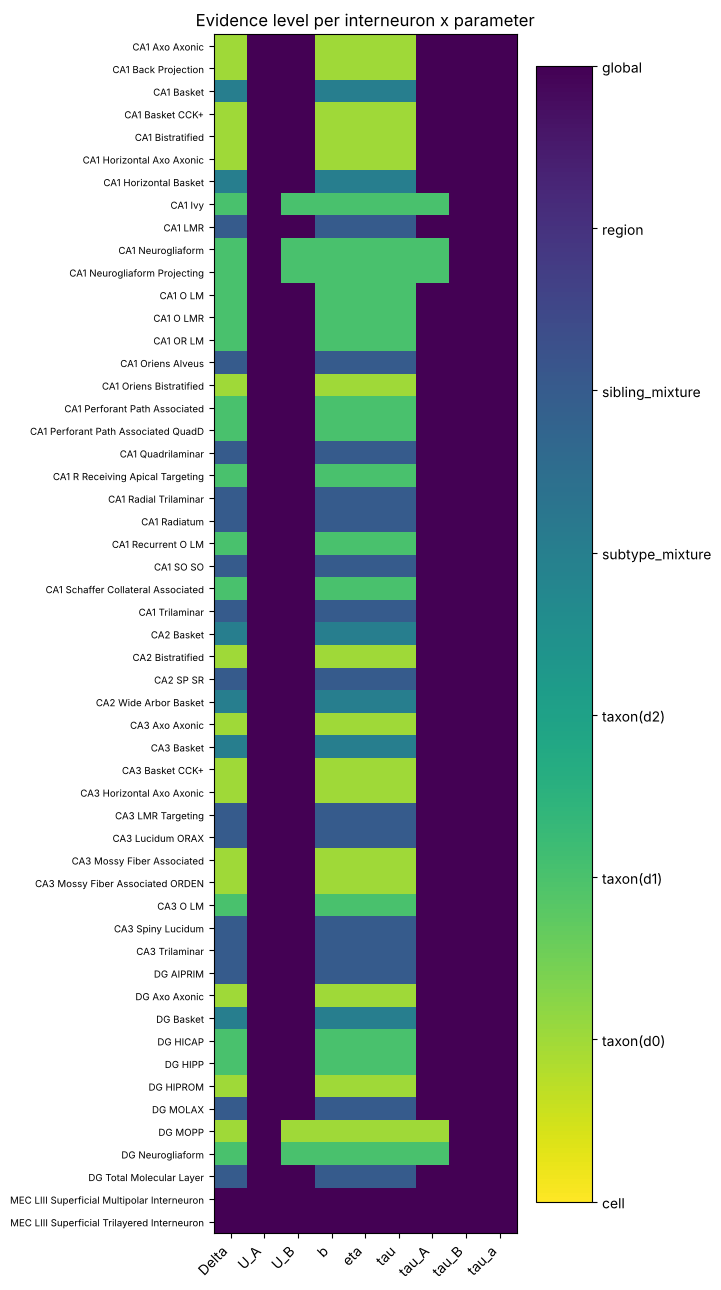

,Delta,U_A,U_B,b,eta,tau,tau_A,tau_B,tau_a
global,2,53,48,2,2,2,48,53,53
sibling_mixture,15,0,0,15,15,15,0,0,0
subtype_mixture,6,0,0,6,6,6,0,0,0
taxon(d0),15,0,1,15,15,15,1,0,0
taxon(d1),15,0,4,15,15,15,4,0,0


In [6]:
cov = kb.coverage()
levels = ["cell", "taxon(d0)", "taxon(d1)", "taxon(d2)", "subtype_mixture", "sibling_mixture", "region", "global"]
code_ = cov.apply(lambda c: c.map({l: i for i, l in enumerate(levels)}))
fig, ax = plt.subplots(figsize=(7, 13))
im = ax.imshow(code_.values, aspect="auto", cmap="viridis_r", vmin=0, vmax=len(levels) - 1)
ax.set_xticks(range(cov.shape[1]), cov.columns, rotation=45, ha="right")
ax.set_yticks(range(cov.shape[0]), cov.index, fontsize=7)
cb = fig.colorbar(im, ticks=range(len(levels))); cb.ax.set_yticklabels(levels)
ax.set_title("Evidence level per interneuron x parameter"); plt.tight_layout(); plt.show()
cov.apply(pd.Series.value_counts).fillna(0).astype(int)

## 4. Morphology vectors ($d_{i\ell}$, $a_{j\ell}$, $a_{jc}$)
Role words from the review (*dominant / major / minor ...*) are converted with the global `role_w_*` weights; `role_converted=True` marks those. CA1 strata are never applied to DG/EC populations.

In [7]:
rows = []
for cell in ["CA1 O LM", "CA1 Bistratified", "CA1 Axo Axonic", "CA1 Schaffer Collateral Associated", "DG HIPP", "CA1 Neurogliaform"]:
    for which in ["dendrite", "axon", "compartment"]:
        r = kb.layer_profile(cell, which)
        if r:
            rows.append({"cell": cell, "which": which, "from": r["subject"], "role_converted": r["role_converted"],
                         **{k: round(v, 2) for k, v in r["profile"].items()}})
pd.DataFrame(rows).fillna("")

,cell,which,from,role_converted,SO,ALV,SLM,unassigned,distal_dendrite,SR,SP,basal_dendrite,oblique_dendrite,soma,AIS,H,OML,MML,nonsynaptic_volume,dendrite_unspecified
0,CA1 O LM,dendrite,OLM,True,0.62,0.37,,,,,,,,,,,,,,
1,CA1 O LM,axon,OLM,False,0.07,,0.9,0.03,,,,,,,,,,,,
2,CA1 O LM,compartment,OLM,True,,,,,1.0,,,,,,,,,,,
3,CA1 Bistratified,dendrite,BIC,True,0.5,,0.0,,,0.5,,,,,,,,,,
4,CA1 Bistratified,axon,BIC,False,0.5,,,,,0.4,0.1,,,,,,,,,
5,CA1 Bistratified,compartment,BIC,True,,,,,,,,0.5,0.5,0.0,,,,,,
6,CA1 Axo Axonic,dendrite,AAC,True,0.16,0.32,0.32,,,0.04,0.16,,,,,,,,,
7,CA1 Axo Axonic,axon,AAC,True,0.17,,,,,,0.83,,,,,,,,,
8,CA1 Axo Axonic,compartment,AAC,False,,,,,,,,,,,1.0,,,,,
9,CA1 Schaffer Collateral Associated,dendrite,CCK_DT,True,0.25,,0.25,,,0.25,0.25,,,,,,,,,


## 5. Hand-off to the ODE
`ode_inputs()` returns arrays in netlist matrix order, the signed coupling in state convention `M[post, pre]`, and `W0 = M / ρ(|M|)`. Read the warnings: the netlist weight already contains $\tau_{ij}$, $c_{ij}$ and $\kappa_j$.

In [8]:
ode = kb.ode_inputs(point="median", weight="m_ij")
print("populations:", len(ode["names"]), " interneurons:", ode["is_inhibitory"].sum(), " rho(|M|) =", round(ode["rho"], 1))
for w in ode["warnings"]:
    print(" -", w)
pd.DataFrame({k: v for k, v in ode["params"].items()}, index=ode["names"])[ode["is_inhibitory"]].round(3).head(12)

populations: 85  interneurons: 53  rho(|M|) = 28730.6
 - U_stp is NOT in m_ij; U_A is free to carry it.
 - m_ij already contains axonal-dendritic overlap c_ij; do not multiply Omega_morph (a_layer x d_layer) into J again.
 - m_ij already integrates synaptic decay (charge). Use tau_A for kinetics only: with tau_A s' = -s + U r the steady-state gain is tau-independent; s' = -s/tau_A + U r would count tau twice.
 - m_ij includes the target's Izhikevich transfer slope kappa_j while the MPR mass supplies its own transfer function; use weight='w_ij' (kappa removed) or fix the MPR gain, not both.


,Delta,U_A,U_B,b,eta,tau,tau_A,tau_B,tau_a
CA1 Axo Axonic,0.089,0.5,0.034,5.376,-0.257,13.174,6.0,150.0,100.0
CA1 Back Projection,0.133,0.5,0.034,95.086,-0.217,35.428,6.0,150.0,100.0
CA1 Basket,0.075,0.5,0.034,11.573,-0.181,13.710,6.0,150.0,100.0
CA1 Basket CCK+,0.064,0.5,0.034,24.913,-0.105,14.268,6.0,150.0,100.0
CA1 Bistratified,0.089,0.5,0.034,5.376,-0.257,13.174,6.0,150.0,100.0
CA1 Horizontal Axo Axonic,0.089,0.5,0.034,5.376,-0.257,13.174,6.0,150.0,100.0
CA1 Horizontal Basket,0.075,0.5,0.034,11.573,-0.181,13.710,6.0,150.0,100.0
CA1 Ivy,0.215,0.5,0.434,37.630,-0.532,36.482,60.0,150.0,100.0
CA1 LMR,0.128,0.5,0.034,31.694,-0.316,30.922,6.0,150.0,100.0
CA1 Neurogliaform,0.215,0.5,0.434,37.630,-0.532,36.482,60.0,150.0,100.0


### Wiring check: the interneuron-only subnetwork
MPR/QIF mass per population (project knowledge §4). **Not a biological prediction** — E populations are left out and `g`, `I_ext` are arbitrary. It only checks that the arrays plug into the equations.

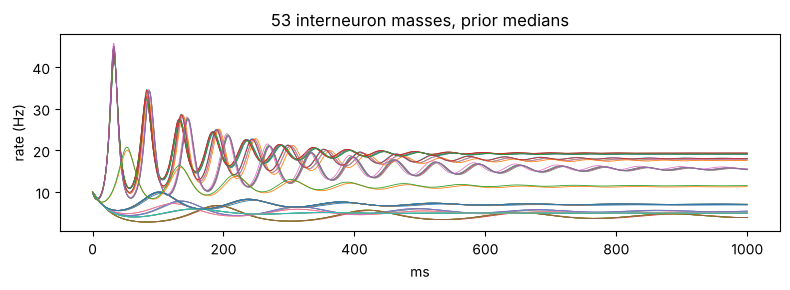

In [9]:
from scipy.integrate import solve_ivp
I = ode["is_inhibitory"]; P = {k: v[I] for k, v in ode["params"].items()}
W = ode["W0"][np.ix_(I, I)]; N = int(I.sum()); g, I_ext = 20.0, 1.0

def mpr(t, x):
    r, v, a, sA, sB = x.reshape(5, N)
    tau = P["tau"]
    I_rec = g * W @ (sA + sB)
    dr = (P["Delta"] / (np.pi * tau) + 2 * r * v) / tau
    dv = (v**2 + P["eta"] + I_ext + I_rec - (np.pi * tau * r)**2 - a) / tau
    da = (-a + P["b"] * r) / P["tau_a"]
    dA = (-sA + P["U_A"] * r) / P["tau_A"]
    dB = (-sB + P["U_B"] * r) / P["tau_B"]
    return np.concatenate([dr, dv, da, dA, dB])

x0 = np.concatenate([np.full(N, 0.01), np.full(N, -0.5), np.zeros(3 * N)])
sol = solve_ivp(mpr, (0, 1000), x0, method="LSODA", max_step=1.0)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(sol.t, 1e3 * sol.y[:N].T, lw=0.6); ax.set_xlabel("ms"); ax.set_ylabel("rate (Hz)")
ax.set_title("53 interneuron masses, prior medians"); plt.tight_layout(); plt.show()

## 6. Prior samples for uncertainty-aware continuation
Independent draws per parameter; feed each draw to the continuation code to get $p(\lambda_H)$, $p(\lambda_F)$.

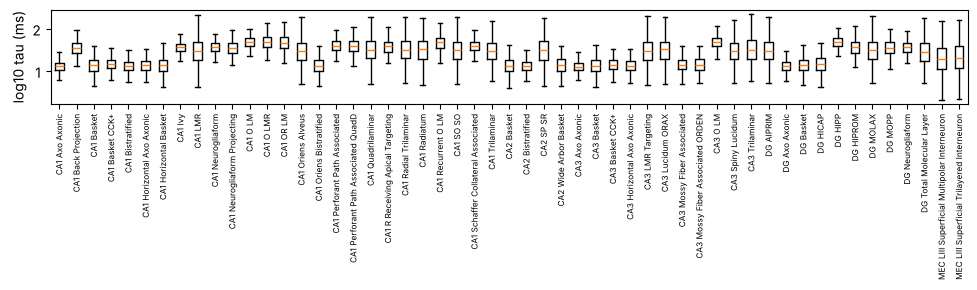

In [10]:
S = kb.sample(n_samples=500, seed=1)
names = kb.interneurons()
fig, ax = plt.subplots(figsize=(10, 3))
ax.boxplot(np.log10(S["tau"]), showfliers=False); ax.set_xticks(range(1, len(names) + 1), names, rotation=90, fontsize=6)
ax.set_ylabel("log10 tau (ms)"); plt.tight_layout(); plt.show()

## 7. Functional queries: what does a cell do, under a condition, at a location?
`kb.describe(cell, condition=..., stimulus_at=..., inhibits_at=...)` returns a readable profile built from literature function statements, anatomy, pathway overlap, the netlist, and receptor effects.

- `inhibits_at`: where the cell's **output** lands (`'distal'`, `'perisomatic'`, `'AIS'`, `'SLM'`, ...)
- `stimulus_at`: where **input** arrives on the interneuron's dendrites, or a pathway (`'TA'`, `'SC'`, `'PP'`, ...)
- `condition`: `'ACh'`, `'opioid'`, `'eCB'`, `'CCK'`, `'theta'`, `'trains'`, `'CFC'`, a receptor (`'MOR'`), or a list

In [11]:
kb.describe("CA1 O LM", condition="ACh", stimulus_at="distal", inhibits_at="distal")

CA1 O LM  [OLM, CA1]
  markers: PV+, SST+, NPY-

FUNCTION
  role: feedback  [OLM p.1627]
  - Feedback inhibition of distal apical tufts that gates entorhinal and nucleus reuniens input  [OLM p.1627]

OUTPUT (where it inhibits)
  compartments: distal_dendrite 1.00  [OLM p.1627]
  layers: SLM 0.90, SO 0.07, unassigned 0.03  [OLM p.1627]
  co-localised with Temporoammonic (EC -> CA1) (TA) input: overlap 0.90
  co-localised with Nucleus reuniens -> CA1 (NRe) input: overlap 0.90
  netlist: 14 target populations; share of weight onto principal cells 1% (m_ij) / 15% (w_ij); strongest: CA1 LMR, CA1 Perforant Path Associated QuadD, CA1 Perforant Path Associated

INPUT (what recruits it)
  dendrites: SO 0.62, ALV 0.37  [OLM p.1627]
  recruited by CA1 pyramidal collaterals (CA1_rec, feedback / local): overlap 0.58
  recruited by Schaffer collateral (SC, feedforward): overlap 0.23
  strongest excitatory drivers (netlist): CA3 Pyramidal, CA3c Pyramidal, CA2 Pyramidal
  strongest inhibitory inputs (

In [12]:
kb.describe("CA1 Basket CCK+", condition=["eCB", "opioid"], inhibits_at="perisomatic")

CA1 Basket CCK+  [CCKBC, CA1]
  markers: PV-, CCK+, CB1+, 5HT3A+

FUNCTION
  - Prolonged, temporally imprecise perisomatic inhibition (asynchronous release)  [CCKBC p.1661]

OUTPUT (where it inhibits)
  compartments: soma 0.50, proximal_dendrite 0.50  [CCKBC p.1624]
  layers: SP 1.00  [CCKBC p.1624]
  netlist: 10 target populations; share of weight onto principal cells 4% (m_ij) / 25% (w_ij); strongest: CA1 Horizontal Basket, CA1 Radial Trilaminar, CA1 Basket

INPUT (what recruits it)
  dendrites: ALV 0.20, SO 0.20, SP 0.20, SR 0.20, SLM 0.20  [CCKBC p.1625]
  recruited by Schaffer collateral (SC, feedforward): overlap 0.20
  recruited by Temporoammonic (EC -> CA1) (TA, feedforward): overlap 0.20
  recruited by Nucleus reuniens -> CA1 (NRe, feedforward): overlap 0.20
  recruited by CA1 pyramidal collaterals (CA1_rec, feedback / local): overlap 0.20
  strongest excitatory drivers (netlist): CA3c Pyramidal, EC LIII Pyramidal Stellate, CA3 Pyramidal
  strongest inhibitory inputs (netlist)

`kb.find(...)` asks the reverse question across all 53 interneurons and returns a DataFrame.

In [13]:
# Which CA1 interneurons inhibit distal dendrites, and what does opioid tone do to them?
kb.find(inhibits_at="distal", region="CA1", condition="opioid")[
    ["cell", "family", "output_frac_at_location", "gates", "condition_net", "condition_effects"]]

,cell,family,output_frac_at_location,gates,condition_net,condition_effects
0,CA1 O LM,OLM,1.0,"TA, NRe",less inhibition (disinhibits its targets),Delta-opioid inhibition of O-LMs is proposed to release temporoammonic (EC) ...
1,CA1 O LMR,OLM,1.0,"TA, NRe",less inhibition (disinhibits its targets),Delta-opioid inhibition of O-LMs is proposed to release temporoammonic (EC) ...
2,CA1 OR LM,OLM,1.0,"TA, NRe",less inhibition (disinhibits its targets),Delta-opioid inhibition of O-LMs is proposed to release temporoammonic (EC) ...
3,CA1 Perforant Path Associated,PPA,1.0,"TA, NRe",unknown (no claims),NaN
4,CA1 Perforant Path Associated QuadD,PPA,1.0,"TA, NRe",unknown (no claims),NaN
5,CA1 Recurrent O LM,OLM,1.0,"TA, NRe",less inhibition (disinhibits its targets),Delta-opioid inhibition of O-LMs is proposed to release temporoammonic (EC) ...


In [14]:
# Which interneurons are recruited when entorhinal (temporoammonic) input arrives?
kb.find(stimulus_at="TA")[["cell", "family", "input_frac_at_location", "recruited_by", "gates", "function"]]

,cell,family,input_frac_at_location,recruited_by,gates,function
0,CA1 Neurogliaform Projecting,NGFC,1.00,"TA, NRe","TA, NRe",Feedforward gating of entorhinal and nucleus reuniens input in s.l.m.
1,CA1 Neurogliaform,NGFC,1.00,"TA, NRe","TA, NRe",Feedforward gating of entorhinal and nucleus reuniens input in s.l.m.
2,CA1 Axo Axonic,AAC,0.32,"TA, NRe, CA1_rec",NaN,Controls principal-cell spike generation by inhibiting the axon initial segment
3,CA1 Horizontal Axo Axonic,AAC,0.32,"TA, NRe, CA1_rec",NaN,Controls principal-cell spike generation by inhibiting the axon initial segment
4,CA1 Perforant Path Associated,PPA,0.25,"SC, TA, NRe, CA1_rec","TA, NRe",Inhibition co-aligned with entorhinal and nucleus reuniens input on distal a...
5,CA1 R Receiving Apical Targeting,ADI,0.25,"SC, TA, NRe, CA1_rec",SC,NaN
6,CA1 Perforant Path Associated QuadD,PPA,0.25,"SC, TA, NRe, CA1_rec","TA, NRe",Inhibition co-aligned with entorhinal and nucleus reuniens input on distal a...
7,CA1 Schaffer Collateral Associated,SCA,0.25,"SC, TA, NRe, CA1_rec",SC,Inhibition co-aligned with CA3 Schaffer collateral input on oblique and basa...
8,CA1 Basket CCK+,CCKBC,0.20,"SC, TA, NRe, CA1_rec",NaN,"Prolonged, temporally imprecise perisomatic inhibition (asynchronous release)"


In [15]:
# Repetitive input: who inhibits early, who late?
kb.find(condition="trains")[["cell", "family", "main_output", "condition_effects"]].dropna(subset=["condition_effects"])

,cell,family,main_output,condition_effects
3,CA1 Basket CCK+,CCKBC,soma,release mode: asynchronous (N-type channels loosely coupled; long asynchrono...
4,CA1 Bistratified,BIC,basal_dendrite,Presumed late-epoch dendritic inhibitor during repetitive input | excitatory...
11,CA1 O LM,OLM,distal_dendrite,"Late, persistent dendritic inhibition that grows as facilitating input build..."
12,CA1 O LMR,OLM,distal_dendrite,"Late, persistent dendritic inhibition that grows as facilitating input build..."
13,CA1 OR LM,OLM,distal_dendrite,"Late, persistent dendritic inhibition that grows as facilitating input build..."
15,CA1 Oriens Bistratified,BIC,basal_dendrite,Presumed late-epoch dendritic inhibitor during repetitive input | excitatory...
16,CA1 Perforant Path Associated,PPA,distal_dendrite,release mode: asynchronous
17,CA1 Perforant Path Associated QuadD,PPA,distal_dendrite,release mode: asynchronous
19,CA1 R Receiving Apical Targeting,ADI,apical_shaft,release mode: asynchronous
22,CA1 Recurrent O LM,OLM,distal_dendrite,"Late, persistent dendritic inhibition that grows as facilitating input build..."


## 8. What is a cell known to do? (literature / experiments)
`kb.known(cell, topic=..., condition=...)` lists everything the KB holds about a population, grouped by topic, each line traced to the review page **and the primary papers it cites** (Pelkey's 1,282-entry bibliography is in `review_reference`).

Topics: `identity, anatomy, physiology, synaptic, function, neuromodulation, oscillation, plasticity, behavior, disease`.

In [16]:
kb.known("CA1 O LM")

CA1 O LM  [OLM]

IDENTITY
  - mGluR1a+ (High dendritic immunoreactivity)
      OLM p.1628 | review | conf 0.76 | Baude 1993; Ferraguti 2004; Klausberger 2009
  - NPY- (Anatomically identified O-LMs repeatedly fail to immunostain for NPY)
      OLM p.1627 | review | conf 0.66 | Katona 2014; Oliva 2000; Forro 2015
  - Embryonic origin: MGE and CGE
      OLM p.1628 | review | conf 0.66
  - PV low (Expressed at much lower levels than AAC/PVBC/BiC)
      OLM p.1627 | review | conf 0.57 | Ferraguti 2004; Forro 2015; Katona 2014
  - Elfn1+ (Suggested to be O-LM specific)
      OLM p.1628 | review | conf 0.57 | Katona 2014; Sylwestrak 2012
  - 5HT3A (subset) (CGE-derived subset is 5-HT3AR+)
      OLM p.1628 | review | conf 0.57 | Bezaire 2013; Chittajallu 2013; Lee 2010
  - Reelin (subset) (Frequently co-expressed)
      OLM p.1627 | review | conf 0.47
  - SST+ (Defining marker of O-LM / HIPP / Martinotti)
      OLM_FAMILY p.1627 | review | conf 0.85

ANATOMY & CONNECTIVITY
  - Soma laminar di

In [17]:
kb.known("CA1 Bistratified", topic=["oscillation", "plasticity"])

CA1 Bistratified  [BIC]   filters: topic=['oscillation', 'plasticity']

NETWORK OSCILLATIONS
  - Theta phase locking: locked [under theta]
      BIC p.1699 | review | conf 0.66
  - Strongly phase-locked to kainate-evoked CA3 gamma while pyramidal cells fire sparsely [under gamma]
      BIC p.1695 | review | conf 0.66 | Gloveli 2005
  - Strongest depth of gamma modulation among CA1 interneurons in vivo [under gamma]
      BIC p.1696 | review | conf 0.66 | Tukker 2007
  - Fire during SWRs (among the most active cells with pyramidal cells and PVBCs) [under SWR]
      BIC p.1698 | review | conf 0.66 | Klausberger 2004
  - Strongly phase-locked to intrinsic CA1 gamma (in vitro) [under gamma]
      BIC p.1696 | review | conf 0.62 | Craig 2015

PLASTICITY
  - MGE-derived CA1 interneurons express only CP-AMPARs at Schaffer collateral synapses (substrate for anti-Hebbian LTP)
      BIC p.1676 | review | conf 0.47 | Matta 2013

CAVEATS
  * no finding in the KB is about this exact netlist type; e

`kb.findings(...)` asks across all cells: one row per finding at the level it was reported, plus the netlist populations that inherit it.

In [18]:
# Which cells fire (or stay silent) during sharp wave-ripples?
kb.findings(condition="SWR")[["subject", "finding", "primary_refs", "netlist_cells"]]

,subject,finding,primary_refs,netlist_cells
0,AAC,Silent during SWRs,Klausberger 2003,"CA1 Axo Axonic, CA1 Horizontal Axo Axonic, CA3 Axo Axonic, CA3 Horizontal Ax..."
1,BIC,Fire during SWRs (among the most active cells with pyramidal cells and PVBCs),Klausberger 2004,"CA1 Bistratified, CA1 Oriens Bistratified, CA2 Bistratified"
2,CCKBC,"Heterogeneous during SWRs: some cells increase, others decrease firing",Klausberger 2005,"CA1 Basket CCK+, CA3 Basket CCK+"
3,IVY,Do not participate in SWRs (silent in CA3 slices too),Fuentealba 2008; Takács 2012,CA1 Ivy
4,OLM,Silent during SWRs under anesthesia,Klausberger 2003,"CA1 O LM, CA1 O LMR, CA1 OR LM, CA1 Recurrent O LM, CA3 O LM"
5,OLM,"Fire during SWRs in awake animals and are recruited into CA1 SWRs in vivo, b...",Varga 2012; Pangalos 2013,"CA1 O LM, CA1 O LMR, CA1 OR LM, CA1 Recurrent O LM, CA3 O LM"
6,PPA,Silent during SWRs under anesthesia,Klausberger 2005,"CA1 Perforant Path Associated, CA1 Perforant Path Associated QuadD"
7,PVBC,Very active during SWRs (anesthetized and awake),Klausberger 2003; Klausberger 2005; Lapray 2012; Varga 2012,(none in netlist)
8,PVBC,Stimulating a single PVBC is sufficient to generate a SWR in CA3 slices,Ellender 2010,(none in netlist)
9,PVBC,PVBC perisomatic inhibition is a main source of the SWR field signal,Hájos 2013,(none in netlist)


In [19]:
# Disease findings; .to_frame() on known() gives the same columns for one cell
kb.findings(topic="disease")[["subject", "finding", "locator", "primary_refs"]]

,subject,finding,locator,primary_refs
0,CCKBC,Pilocarpine epilepsy: loss of CCKBC inhibition onto CA1 pyramidal cells whil...,p.1706,Wyeth 2010
1,CCKBC,Kindling: spontaneous seizures associated with loss of DG CCK interneurons,p.1706,Sayin 2003
2,DG Basket,Traumatic brain injury: loss of DG CCK- and PV-containing interneurons in th...,p.1706,Toth 1997
3,HIPP,ApoE4 AD model: hippocampal hyperactivity with loss of hilar GABAergic inter...,p.1711,Filippini 2009; Li 2009
4,OLM,Pilocarpine (rat): loss of s.o. interneurons expressing SST or PV (not SST+P...,p.1706,Dinocourt 2003
5,OLM,APP/PS1 Alzheimer model: s.l.m. axon loss and O-LM-specific activation defic...,p.1708,Schmid 2016
6,OLM_FAMILY,SST interneuron loss in at least three independent AD mouse models,p.1708,Ramos 2006; Levenga 2013; Andrews-Zwilling 2010
7,PVBC,Pilocarpine epilepsy: PVBC perisomatic inhibition remains intact while CCKBC...,p.1706,Wyeth 2010
8,PVBC,NRG1/ErbB4 raises PV-cell excitability (Kv1.1 suppression); deleting ErbB4 f...,p.1706,Li; Tan 2011
9,PVBC,Nav1.1 (mostly restricted to PV cells) is reduced in APP mice and AD patients,p.1708,Verret; Wang 2011


In [20]:
# Export one cell's report with DOIs
kb.known("CA1 Basket CCK+").to_frame()[["section", "text", "condition", "subject", "locator", "primary_refs", "primary_dois"]].head(15)

,section,text,condition,subject,locator,primary_refs,primary_dois
0,Identity,CCK+ (CCK-8 in somatodendritic and axonal compartments),NaN,CCKBC,p.1626,,
1,Identity,CB1+ (Terminals heavily endowed with CB1R),NaN,CCKBC,p.1626,Bodor 2005; Freund 2003; Katona 1999,; 10.1016/S0166-2236(03)00227-3;
2,Identity,Embryonic origin: CGE,NaN,CCKBC,p.1626,Chittajallu 2013; Lee 2010; Morozov 2009; Tricoire 2011,10.1038/nn.3538; 10.1523/JNEUROSCI.1869-10.2010; 10.1093/cercor/bhp028; 10.1...
3,Identity,PV- (CCK and PV basket populations are distinct cohorts (CGE vs MGE)),NaN,CCKBC,p.1623-1626,,
4,Identity,VIP (subset) (Subset VIP+; subset VGluT3+; many neither),NaN,CCKBC,p.1626,Acsády 1996; Bezaire 2013; Somogyi 2004,; 10.1002/hipo.22141;
5,Identity,VGluT3 (subset),NaN,CCKBC,p.1626,Acsády 1996; Bezaire 2013; Somogyi 2004,; 10.1002/hipo.22141;
6,Anatomy & connectivity,Axonal laminar distribution: Perisomatic within s.p.,NaN,CCKBC,p.1624,,
7,Anatomy & connectivity,Axonal postsynaptic-compartment distribution: Soma and proximal dendrites,NaN,CCKBC,p.1624,,
8,Anatomy & connectivity,Fraction of CA1 interneurons: ~0.09,NaN,CCKBC,p.1624,Bezaire 2013,10.1002/hipo.22141
9,Anatomy & connectivity,Cell count in one rodent CA1: ~3600 cells,NaN,CCKBC,p.1624,Bezaire 2013,10.1002/hipo.22141


## 9. Curation loop
New literature goes in as **claims** (with a page locator); fitted values go back as **model estimates**, never as claims.

```python
kb.db.execute("INSERT INTO source (short_ref, citation, doi, year, source_type) VALUES (?,?,?,?,?)",
              ("Bartos2002", "Bartos M et al. PNAS 99:13222 (2002)", "10.1073/pnas.192233099", 2002, "primary"))
kb.add_claim("t:PVBC", "gabaa_decay_ratio_vs_fast", source="Bartos2002", evidence_class="measurement",
             locator="Fig. 2", value_num=1.0, confidence=0.8)

kb.record_estimates("theta fit v1", [("CA1 O LM", "tau", 41.2, 3.0)], observables="theta freq", code_ref="git:abc123")
```

In [21]:
# Raw SQL is always available, e.g. every claim that reaches CA1 O LM, most specific first:
pd.read_sql("""SELECT property_code, inherit_rank, confidence, mapping_confidence, claim_id
               FROM v_cell_claim WHERE netlist_name = 'CA1 O LM' ORDER BY inherit_rank, property_code""", kb.db).head(20)

,property_code,inherit_rank,confidence,mapping_confidence,claim_id
0,axon_compartment_distribution,1,0.80,0.95,139
1,axon_layer_distribution,1,0.85,0.95,138
2,cell_count_CA1,1,0.70,0.95,135
3,circuit_role,1,0.85,0.95,233
4,crosses_fissure,1,0.80,0.95,143
5,dendrite_layer_distribution,1,0.85,0.95,137
6,embryonic_origin,1,0.70,0.95,151
7,experimental_finding,1,0.60,0.95,258
8,experimental_finding,1,0.65,0.95,260
9,experimental_finding,1,0.60,0.95,266
